In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)


Using: cuda


In [2]:
import torch, torchvision, torchaudio

print("Torch:", torch.__version__, "CUDA:", torch.version.cuda)
print("Torchvision:", torchvision.__version__)
print("Torchaudio:", torchaudio.__version__)
print("GPU aktif:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.14.1+cu132 CUDA: 13.2
Torchvision: 0.29.1+cu132
Torchaudio: 2.11.0+cpu
GPU aktif: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
import pandas as pd

df_train = pd.read_csv('../../data/sentiment-analysis-on-movie-reviews/train.tsv', sep='\t')
df_test = pd.read_csv('../../data/sentiment-analysis-on-movie-reviews/test.tsv', sep='\t')

df_train.head()

,PhraseId,SentenceId,Phrase,Sentiment
0,1,1,A series of escapades demonstrating the adage ...,1
1,2,1,A series of escapades demonstrating the adage ...,2
2,3,1,A series,2
3,4,1,A,2
4,5,1,series,2


In [4]:
df_train = df_train.drop('PhraseId', axis=1)
df_train = df_train.drop('SentenceId', axis=1)

df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 156060 entries, 0 to 156059
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Phrase     156060 non-null  str  
 1   Sentiment  156060 non-null  int64
dtypes: int64(1), str(1)
memory usage: 2.4 MB


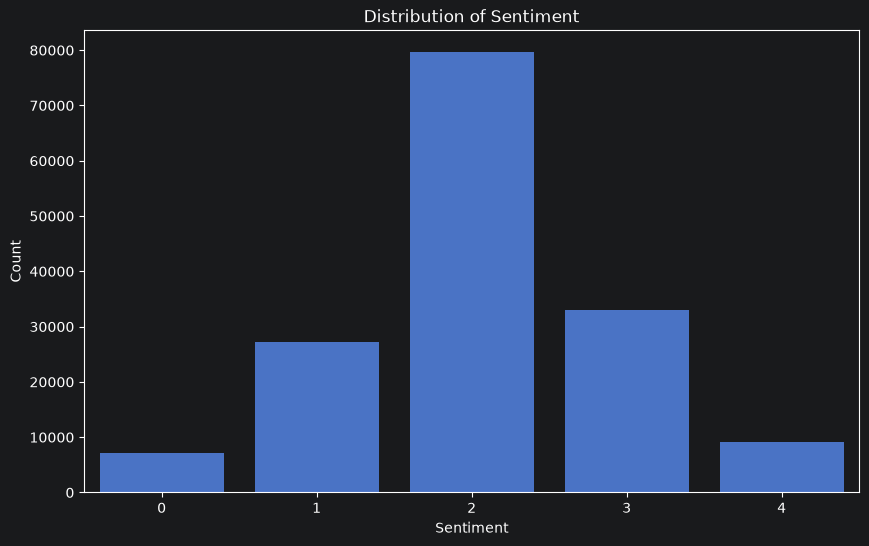

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.countplot(x=df_train['Sentiment'])
plt.title('Distribution of Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

In [6]:
import tensorflow as tf

print("GPU tersedia:", tf.config.list_physical_devices('GPU'))


GPU tersedia: []


In [7]:
import pandas as pd
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight

import numpy as np

# 1. Preprocessing ringan
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)   # hapus angka/simbol, biarkan huruf
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_train["clean_phrase"] = df_train["Phrase"].apply(clean_text)

# 2. Tokenizer & sequence
tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(df_train["clean_phrase"])

X_seq = tokenizer.texts_to_sequences(df_train["clean_phrase"])
X_pad = pad_sequences(X_seq, maxlen=100)   # padding ke panjang 100 kata

# 3. Label (ubah ke one-hot jika multi-class)
y = to_categorical(df_train["Sentiment"], num_classes=5)

# 4. Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_pad, y, test_size=0.2, random_state=42, stratify=df_train["Sentiment"]
)

# 5. Bangun model LSTM
model = Sequential([
    Embedding(input_dim=20000, output_dim=128, input_length=100),
    LSTM(128, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(5, activation="softmax")  # 5 kelas
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# 6. Training
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(df_train["Sentiment"]),
    y=df_train["Sentiment"]
)
class_weights = dict(enumerate(class_weights))

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=128,
    verbose=1,
    class_weight=class_weights
)

# 7. Evaluasi
y_pred = model.predict(X_test)
y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test.argmax(axis=1)

print(classification_report(y_true, y_pred_classes))


C:\Users\hajar\Documents\gemastik-xix\JupyterProject\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
878/878 ━━━━━━━━━━━━━━━━━━━━ 485s 542ms/step - accuracy: 0.4760 - loss: 1.2095 - val_accuracy: 0.5098 - val_loss: 1.1297
Epoch 2/5
878/878 ━━━━━━━━━━━━━━━━━━━━ 267s 304ms/step - accuracy: 0.5704 - loss: 0.9153 - val_accuracy: 0.5437 - val_loss: 1.0455
Epoch 3/5
878/878 ━━━━━━━━━━━━━━━━━━━━ 107s 122ms/step - accuracy: 0.6059 - loss: 0.8113 - val_accuracy: 0.5618 - val_loss: 1.0082
Epoch 4/5
878/878 ━━━━━━━━━━━━━━━━━━━━ 104s 119ms/step - accuracy: 0.6252 - loss: 0.7440 - val_accuracy: 0.5431 - val_loss: 1.0365
Epoch 5/5
878/878 ━━━━━━━━━━━━━━━━━━━━ 106s 121ms/step - accuracy: 0.6390 - loss: 0.6914 - val_accuracy: 0.5630 - val_loss: 1.0274
976/976 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step
              precision    recall  f1-score   support

           0       0.33      0.69      0.44      1414
           1       0.42      0.56      0.48      5455
           2       0.84      0.58      0.69     15917
           3       0.49      0.44      0.47      6585
           4       0.36      0.